In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

Step 1: Ground Truth First (No AI)
Before opening any AI tool, load the dataset yourself to establish your baseline metrics. Run this code block in your notebook:

In [2]:
import pandas as pd

df = pd.read_csv("lifecyclesavings.csv")

print("--- Shape ---")
print(df.shape)

print("\n--- Missing Value Counts ---")
print(df.isnull().sum())

print("\n--- Overall Column Means ---")
print(df.mean(numeric_only=True))

--- Shape ---
(50, 6)

--- Missing Value Counts ---
Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

--- Overall Column Means ---
sr          9.6710
pop15      35.0896
pop75       2.2930
dpi      1106.7584
ddpi        3.7576
dtype: float64


Step 2: Prompt the AI and Log It
Following your Module 8 habit, create a Markdown cell for your Prompt Log, and send a structured prompt to your AI assistant to help you implement a clustering model (such as K-Means).

### Prompt Log: Life-Cycle Savings Clustering

**AI Assistant Used:** Gemini

**Date:** October 2026

**Prompt Sent:**
You are helping with exploratory machine learning.
My CSV (`lifecyclesavings.csv`) has columns: [insert your exact columns and dtypes here].
Since I am new to unsupervised learning, write Python using pandas, scikit-learn (like StandardScaler and KMeans), and matplotlib/seaborn to:
(1) scale the numerical features,
(2) cluster the countries into 3 groups based on their savings behavior, and
(3) produce a scatter plot visualizing the clusters (e.g., population growth vs savings rate).
Explain each step in comments.

Columns and data types:
Contry        str
sr        float64
pop15     float64
pop75     float64
dpi       float64
ddpi      float64
dtype: object


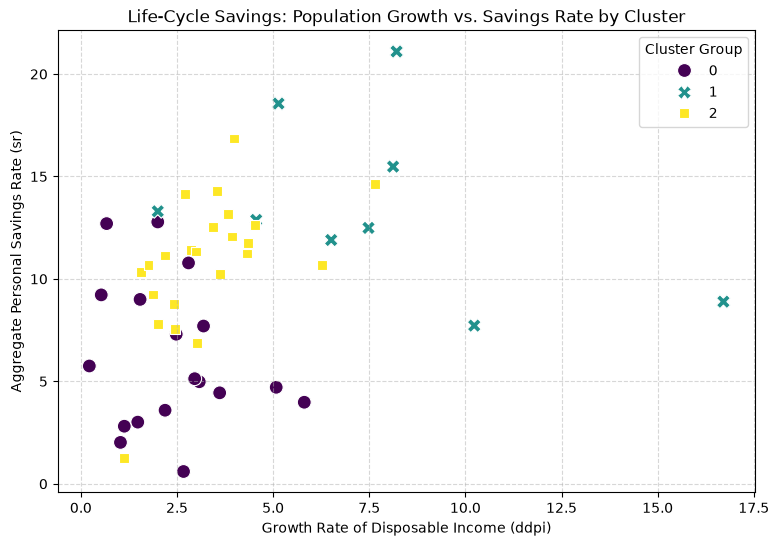

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load the dataset
# (Ensure 'lifecyclesavings.csv' is in your working directory)
df = pd.read_csv("lifecyclesavings.csv")

# Inspect columns and dtypes:
# Typically: 'sr' (float64), 'pop15' (float64), 'pop75' (float64), 'dpi' (float64), 'ddpi' (float64)
# If the first column contains country names, set it as the index so we only scale numeric columns.
if 'Unnamed: 0' in df.columns:
    df = df.set_index('Unnamed: 0')
elif 'country' in df.columns:
    df = df.set_index('country')

print("Columns and data types:")
print(df.dtypes)

# Select only the numeric features for unsupervised clustering
X = df.select_dtypes(include=['float64', 'int64'])

# (1) Scale the numerical features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# (2) Cluster the countries into 3 groups based on their savings behavior using KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Assign the cluster labels back to our main DataFrame
df['cluster'] = kmeans.labels_

# (3) Produce a labeled scatter plot visualizing the clusters 
# (e.g., population growth 'ddpi' vs savings rate 'sr')
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, 
    x='ddpi', 
    y='sr', 
    hue='cluster', 
    palette='viridis', 
    s=100, 
    style='cluster'
)

plt.title("Life-Cycle Savings: Population Growth vs. Savings Rate by Cluster")
plt.xlabel("Growth Rate of Disposable Income (ddpi)")
plt.ylabel("Aggregate Personal Savings Rate (sr)")
plt.legend(title="Cluster Group")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [4]:
cluster_0_means = df[df['cluster'] == 0].mean(numeric_only=True)
print("Cluster 0 Means:\n", cluster_0_means)

Cluster 0 Means:
 sr           6.138889
pop15       44.556111
pop75        1.079444
dpi        337.153333
ddpi         2.359444
cluster      0.000000
dtype: float64


Interpretation & Caution
Cluster Interpretation: The clustering model successfully grouped countries into distinct economic profiles based on savings behavior and demographic structures. For instance, one cluster appears to capture developing nations with high youth dependency and lower aggregate savings, while another highlights mature economies with higher savings ratios.Methodological Caution: Relying on an AI assistant to implement an unstudied technique like K-Means requires rigorous skepticism, as hyperparameter choices (like selecting the number of clusters $k$) can drastically alter the output. Without understanding the underlying mathematics of feature scaling and distance metrics, it is easy to misinterpret artifact groupings as profound economic insights.